# 1. Data loading, validation and EDA

**Where the data comes from.** Real toll logs are not public, so the data is synthetic: `ml/generate_data.py` simulates ~3,400 vehicles making trips along real Maharashtra highway corridors (crossing time = distance / speed), then injects labelled anomalies. It also adds legitimate messiness that detectors must *not* flag (concessions, local-pass tags, a tariff revision, sensor errors, clock skew, benign load spikes). Labels come from the injection process, never from the detection rules.

Every script reads the data through `ml/data_loader.py`, which refuses to continue if a hard check fails.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1]              # notebooks live in ml/notebooks
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "ml"))
import common as C, model_zoo as Z
from common import cfg
from data_loader import load_plazas, load_transactions, validate
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
plazas = load_plazas()
df = load_transactions(plazas=plazas)              # validated, time-ordered, clean index
splits = C.split_time(df)
specs = C.detector_specs(plazas)

## Data validation report

In [2]:
report = validate(df, plazas)
print(json.dumps({k: v for k, v in report.items() if k != "checks_passed"}, indent=2))
print("\nchecks passed:", ", ".join(report["checks_passed"]))

{
  "rows": 49698,
  "tags": 3382,
  "plazas": 19,
  "time_range": [
    "2026-10-01 00:05:49",
    "2026-10-30 23:58:31"
  ],
  "days": 30.0,
  "label_counts": {
    "none": 43114,
    "duplicate_charge": 1500,
    "fare_tampering": 1400,
    "api_flood": 1371,
    "class_mismatch": 1313,
    "cloned_tag": 1000
  },
  "anomaly_rate": 0.1325,
  "amount_INR": {
    "min": 0,
    "median": 110.0,
    "max": 2160
  },
  "req_per_min": {
    "median": 64.0,
    "p99": 2107.149999999994,
    "max": 4993
  },
  "rows_per_tag": {
    "median": 12.0,
    "max": 69
  }
}

checks passed: required columns, no nulls, unique txn_id, datetime timestamps, non-negative amounts and telemetry, known plazas, known labels, plausible axle counts


## Labels
13% of rows are injected anomalies. Each ML detector is responsible for exactly one label (`api_flood`, `fare_tampering`).

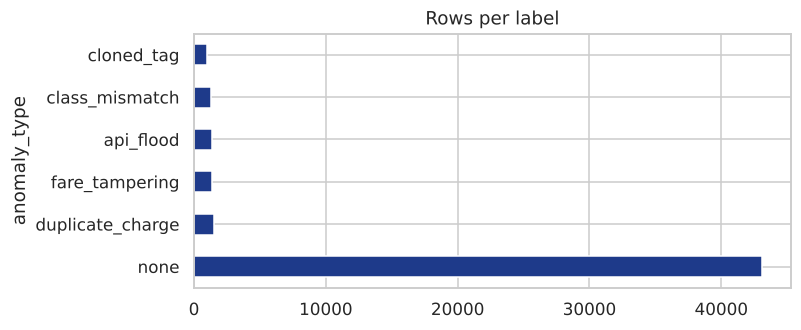

In [3]:
lab = df.anomaly_type.value_counts()
fig, ax = plt.subplots(figsize=(7, 3)); lab.plot.barh(ax=ax, color="#1E3A8A"); ax.set_title("Rows per label"); plt.show()

## Time structure and the chronological split
Rows are time-ordered, so no model sees the future. The dashed line is the tariff revision (legitimate, +10% at three plazas); a model trained before it must not flag it.

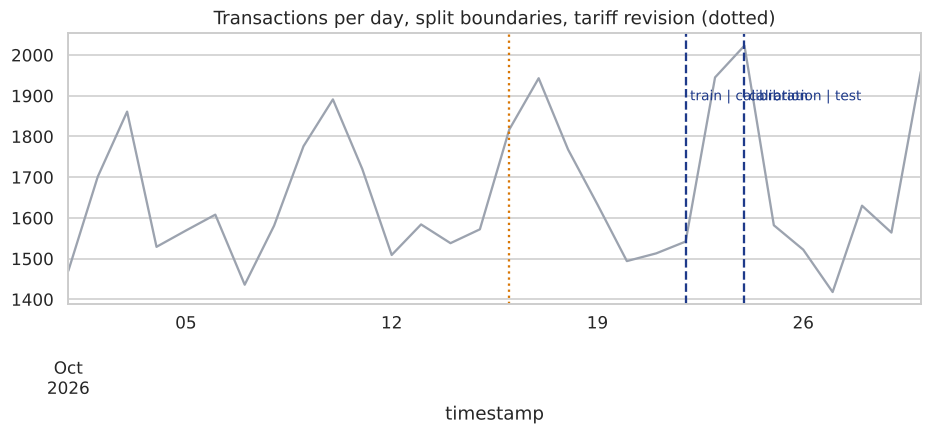

{'train': 34788, 'calibration': 4970, 'test': 9940}


In [4]:
daily = df.groupby(df.timestamp.dt.floor("D")).size()
fig, ax = plt.subplots(figsize=(10, 3.2)); daily.plot(ax=ax, color="#9CA3AF")
bounds = {"train | calibration": splits["calibration"].timestamp.min(), "calibration | test": splits["test"].timestamp.min()}
for k, t in bounds.items(): ax.axvline(t, color="#1E3A8A", ls="--"); ax.text(t, ax.get_ylim()[1] * .92, " " + k, color="#1E3A8A", fontsize=9)
ax.axvline(pd.Timestamp("2026-10-01") + pd.Timedelta(days=15), color="#D97706", ls=":"); ax.set_title("Transactions per day, split boundaries, tariff revision (dotted)"); plt.show()
print({k: len(v) for k, v in splits.items()})

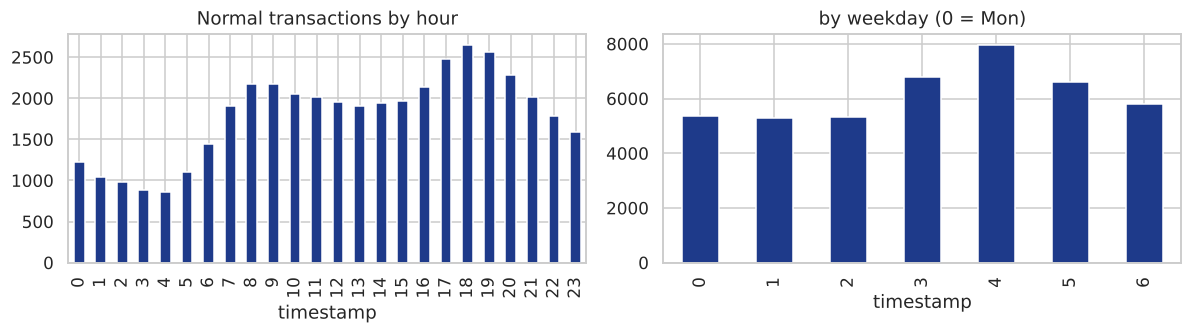

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
n = df[df.anomaly_type == "none"]
n.groupby(n.timestamp.dt.hour).size().plot.bar(ax=ax[0], color="#1E3A8A", title="Normal transactions by hour")
n.groupby(n.timestamp.dt.dayofweek).size().plot.bar(ax=ax[1], color="#1E3A8A", title="by weekday (0 = Mon)"); plt.tight_layout(); plt.show()

## Impossible travel (cloned tags)
Implied speed between consecutive passages of one tag. Normal traffic stays far below the 140 km/h limit; clones sit far above it. Plaza clock skew and sensor noise keep the normal tail honest.

normal: p99 464 km/h, max 98689 | clones: median 368 km/h


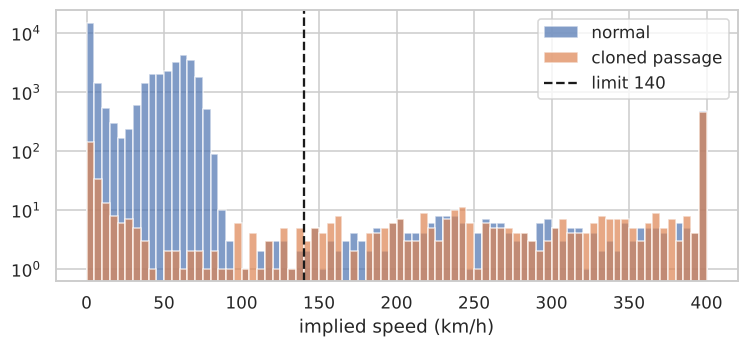

In [6]:
d = df.merge(plazas[["plaza_id", "lat", "lon"]], on="plaza_id").sort_values(["tag_id", "timestamp"]); g = d.groupby("tag_id")
dist = cfg.haversine_km(g.lat.shift(), g.lon.shift(), d.lat, d.lon)
d["speed"] = dist / ((d.timestamp - g.timestamp.shift()).dt.total_seconds() / 3600).clip(lower=1 / 3600)
normal, clone = d.loc[d.anomaly_type == "none", "speed"].dropna(), d.loc[d.anomaly_type == "cloned_tag", "speed"].dropna()
print(f"normal: p99 {normal.quantile(.99):.0f} km/h, max {normal.max():.0f} | clones: median {clone.median():.0f} km/h")
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.hist(normal.clip(upper=400), 80, alpha=.7, label="normal"); ax.hist(clone.clip(upper=400), 80, alpha=.7, label="cloned passage")
ax.axvline(cfg.MAX_SPEED_KMH, color="k", ls="--", label="limit 140"); ax.set_yscale("log"); ax.legend(); ax.set_xlabel("implied speed (km/h)"); plt.show()

## API floods: amplitude overlaps, duration does not
Benign spikes and real floods overlap in size (so a threshold alone struggles), but a flood is **sustained** over 5-12 consecutive rows at one plaza while a benign blip is short. That is why the flood model also sees the plaza's recent load (`ctx_req`).

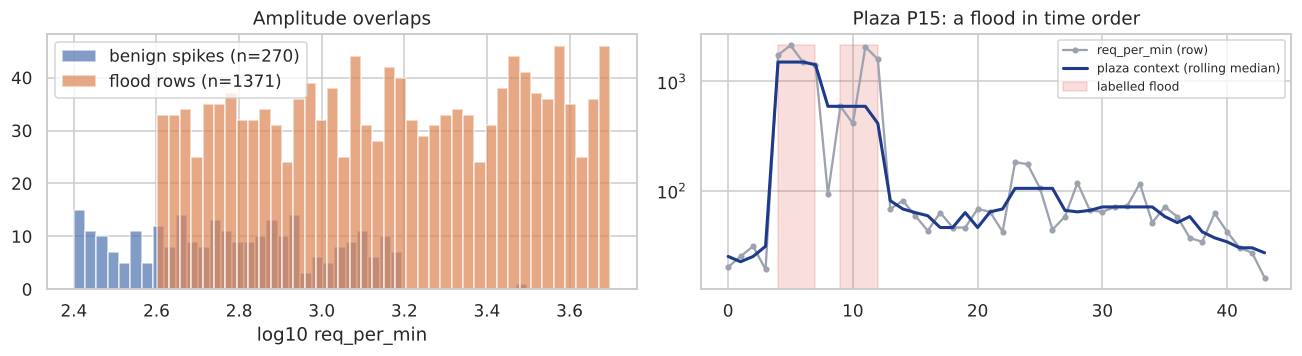

In [7]:
benign = df[(df.anomaly_type == "none") & (df.req_per_min >= 250)]; flood = df[df.anomaly_type == "api_flood"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(np.log10(benign.req_per_min), 40, alpha=.7, label=f"benign spikes (n={len(benign)})"); ax[0].hist(np.log10(flood.req_per_min), 40, alpha=.7, label=f"flood rows (n={len(flood)})")
ax[0].set_xlabel("log10 req_per_min"); ax[0].legend(); ax[0].set_title("Amplitude overlaps")
f = cfg.flood_features(df); first = df.index[df.anomaly_type == "api_flood"][0]; plz = df.loc[first, "plaza_id"]
w = df[df.plaza_id == plz]; pos = w.index.get_loc(first); w = w.iloc[max(0, pos - 25): pos + 40]
ax[1].plot(range(len(w)), w.req_per_min, ".-", color="#9CA3AF", label="req_per_min (row)"); ax[1].plot(range(len(w)), np.expm1(f.loc[w.index, "ctx_req"]), color="#1E3A8A", lw=2, label="plaza context (rolling median)")
ax[1].fill_between(range(len(w)), 0, w.req_per_min.max(), where=(w.anomaly_type == "api_flood").to_numpy(), color="#DC2626", alpha=.15, label="labelled flood"); ax[1].set_yscale("log"); ax[1].legend(fontsize=8); ax[1].set_title(f"Plaza {plz}: a flood in time order"); plt.tight_layout(); plt.show()

## Billing
Billed amount / tariff for the declared class. Legitimate billing sits at a few discrete levels: 1.0, 0.5 (random concession), 0.6 (local-pass tags) and ~1.1 (tariff revision at three plazas). Tampering fills the gaps, including *between* legitimate levels, which is exactly where Isolation Forest is weakest.

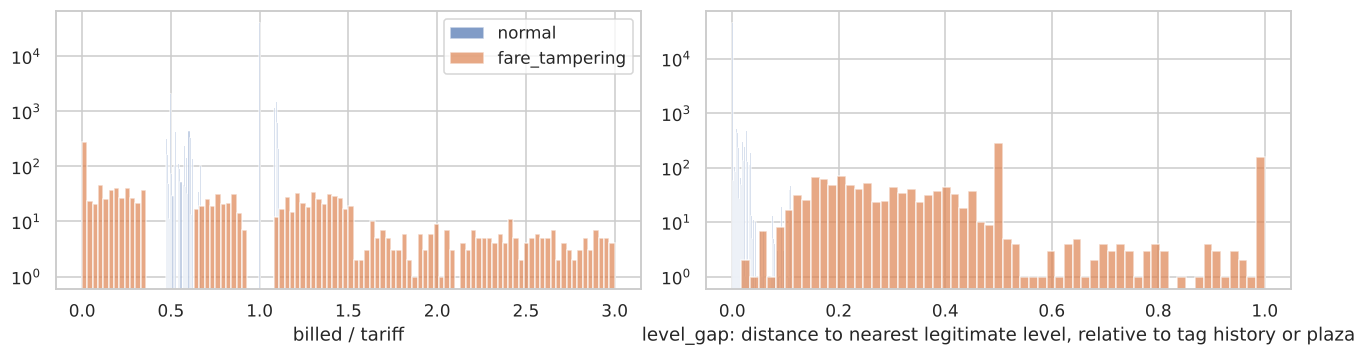

In [8]:
ff = cfg.fare_features(df, plazas)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for lab_, m in [("normal", df.anomaly_type != "fare_tampering"), ("fare_tampering", df.anomaly_type == "fare_tampering")]:
    ax[0].hist(ff.loc[m, "fare_ratio"].clip(upper=3), 100, alpha=.7, label=lab_, log=True)
    ax[1].hist(ff.loc[m, "level_gap"].clip(upper=1), 60, alpha=.7, label=lab_, log=True)
ax[0].set_xlabel("billed / tariff"); ax[0].legend(); ax[1].set_xlabel("level_gap: distance to nearest legitimate level, relative to tag history or plaza"); plt.tight_layout(); plt.show()

## What each class looks like in feature space

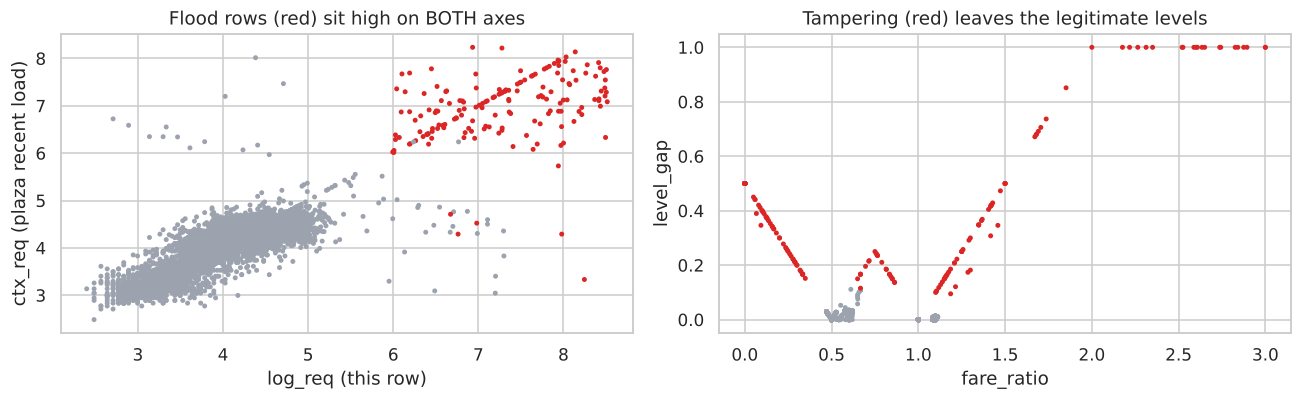

In [9]:
fl = cfg.flood_features(df); s = df.assign(**fl.to_dict("list")).sample(6000, random_state=0)
col = s.anomaly_type.map({"api_flood": "#DC2626"}).fillna("#9CA3AF")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); ax[0].scatter(s.log_req, s.ctx_req, c=col, s=5); ax[0].set_xlabel("log_req (this row)"); ax[0].set_ylabel("ctx_req (plaza recent load)"); ax[0].set_title("Flood rows (red) sit high on BOTH axes")
s2 = df.assign(**ff.to_dict("list")).sample(6000, random_state=0); col2 = s2.anomaly_type.map({"fare_tampering": "#DC2626"}).fillna("#9CA3AF")
ax[1].scatter(s2.fare_ratio.clip(upper=3), s2.level_gap.clip(upper=1), c=col2, s=5); ax[1].set_xlabel("fare_ratio"); ax[1].set_ylabel("level_gap"); ax[1].set_title("Tampering (red) leaves the legitimate levels"); plt.tight_layout(); plt.show()